# Movie / TV Show Subtitle Sentiment & Genre Analyzer
### End-to-end NLP Pipeline
**Flow:** `User Input → Subtitles → Cleaning → Preprocessing → Sentiment → Visualization → ML Classification → Evaluation`
# **API key at [opensubtitles.com](https://www.opensubtitles.com/en/consumers) (in Step 3.)

In [2]:
!pip install requests beautifulsoup4 pandas numpy matplotlib seaborn nltk scikit-learn tensorflow -q
print(" Installation complete")

 Installation complete


In [4]:
# Step 1 — Imports & Setup
import re, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from bs4 import BeautifulSoup

import nltk
for resource in ['vader_lexicon', 'punkt', 'punkt_tab', 'stopwords', 'wordnet', 'omw-1.4']:
    nltk.download(resource, quiet=True)

from nltk.sentiment.vader import SentimentIntensityAnalyzer
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix, ConfusionMatrixDisplay,
                              classification_report)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.utils import to_categorical

warnings.filterwarnings('ignore')
tf.get_logger().setLevel('ERROR')
sns.set_theme(style="whitegrid")
print(" All libraries loaded!")

 All libraries loaded!


In [5]:
#Step 2 — User Input
show_name  = input(" Enter movie or TV show name : ").strip()
show_type  = input(" TV show or movie? (tv / movie): ").strip().lower()
is_tv      = show_type == "tv"

if is_tv:
    num_episodes = int(input(" Number of episodes to analyse (e.g. 6): ").strip() or "6")
else:
    num_episodes = 2   #for a movie

print(f"\n  Analysing  : '{show_name}'")
print(f"    Type       : {'TV Show' if is_tv else 'Movie'}")
print(f"    Segments   : {num_episodes}")

 Enter movie or TV show name :  John Wick
 TV show or movie? (tv / movie):  movie



  Analysing  : 'John Wick'
    Type       : Movie
    Segments   : 2


In [6]:
'''Step 3 — Data Collection
Two modes:
Real subtitles – OpenSubtitles REST API (https://www.opensubtitles.com/en/consumers) 
or
Simulated data(default)'''

#  API key from opensubtitles.com 
OPENSUBTITLES_API_KEY = "dXbWgFRz0uRGtHEQK4QHeKyH0UXVjNg3"   #empty for simulated data

def fetch_opensubtitles(title, api_key):
    """Attempt to download SRT from OpenSubtitles REST API."""
    headers = {
        "Api-Key": api_key,
        "User-Agent": "SubtitleAnalyzer/1.0",
        "Content-Type": "application/json",
    }
    try:
        r = requests.get(
            f"https://api.opensubtitles.com/api/v1/subtitles?query={title}&languages=en",
            headers=headers, timeout=10)
        results = r.json().get("data", [])
        if not results:
            return None
        file_id = results[0]["attributes"]["files"][0]["file_id"]

        dl = requests.post("https://api.opensubtitles.com/api/v1/download",
                           headers=headers, json={"file_id": file_id}, timeout=10)
        link = dl.json().get("link")
        if not link:
            return None
        return requests.get(link, timeout=15).text
    except Exception as e:
        print(f"    API error: {e}")
        return None


# --- Simulated dialogue pools ---
POSITIVE = [
    "This is absolutely wonderful, I'm so happy!",
    "We finally did it! I can't believe we succeeded.",
    "You're the best friend I've ever had.",
    "Everything is going to be okay, I promise.",
    "That was amazing, I've never felt so alive!",
    "I love you more than words can say.",
    "Today was a great day, everything went perfectly.",
    "We won! This is incredible news for everyone.",
    "Thank you, this means everything to me.",
    "I'm so proud of what we've accomplished together.",
    "What a beautiful morning, life feels so good.",
    "You always know how to make me smile.",
    "We actually pulled it off… against all odds."
    "That was insane—and somehow it worked perfectly."
    "You're stronger than you think, don’t forget that."
    "We saved them. That’s what matters."
    "I knew you’d come through in the end."
    "This is bigger than us—and we’re ready for it."
    "We made history today, whether they like it or not."
    "I've never felt this powerful before."
    "We’re not just surviving anymore—we’re winning."
    "You stood your ground. That means everything."
    "Maybe the world isn’t perfect… but it’s still worth fighting for."
    "We turned a disaster into something incredible."
]
NEGATIVE = [
    "I can't believe you would betray me like this.",
    "Everything is falling apart and I don't know what to do.",
    "This is a disaster, we're going to lose everything.",
    "I hate this, why does everything always go wrong?",
    "There's no hope left, we've lost it all.",
    "This is the worst day of my entire life.",
    "How could you do this after everything we've been through?",
    "I'm so angry I can barely breathe right now.",
    "Nothing makes sense anymore, I feel completely lost.",
    "We're surrounded, there is no way out of this.",
    "I'm done trusting people, they always let me down.",
    "I wish none of this had ever happened.",
    "You lied to me from the very beginning."
    "This isn’t a mission anymore—it’s a massacre."
    "We’re way past the point of fixing this."
    "You think this is justice? It’s just revenge."
    "I trusted you—and that was my biggest mistake."
    "Everything we built is collapsing right now."
    "You don’t get to walk away after what you’ve done."
    "This world chews people up and calls it normal."
    "We’re not the heroes here… not even close."
    "I can’t tell what’s real anymore."
    "You knew this would happen and said nothing."
    "There’s blood on all of our hands now."
]
NEUTRAL = [
    "Let's meet at the office tomorrow morning.",
    "The meeting is scheduled for three o'clock.",
    "I'll take the car and be there in twenty minutes.",
    "Can you pass me that file please?",
    "The train arrives at platform seven.",
    "We should review the plan one more time.",
    "I need to make a quick phone call first.",
    "The forecast says it will rain tomorrow.",
    "Let me check the schedule for next week.",
    "Could you explain that one more time please?",
    "I'll have the report ready by Friday.",
    "Shall we grab some coffee before the briefing?",
    "We need a plan before we make the next move."
    "Check the coordinates again, something’s off."
    "Give me five minutes to recalibrate this."
    "We stick to the timeline, no improvising."
    "Let’s run through the scenario one more time."
    "I’ll handle the front—you take the rear exit."
    "The signal is unstable but still readable."
    "We should avoid drawing attention right now."
    "Run diagnostics and report back."
    "We’re operating on limited information here."
    "Adjust the approach and try again."
    "Let’s keep this controlled and precise."
]

def simulate_subtitles(segment, total_segments, n_lines=35):
    random.seed(segment * 37)
    p = segment / max(total_segments, 1)   # 0 → 1

    if p <= 0.20:    # Setup        – mostly upbeat
        w = [0.45, 0.10, 0.45]
    elif p <= 0.50:  # Rising action – tension builds
        w = [0.25, 0.45, 0.30]
    elif p <= 0.75:  # Climax        – darkest point
        w = [0.10, 0.65, 0.25]
    else:            # Resolution    – hopeful end
        w = [0.55, 0.10, 0.35]

    pools = [POSITIVE, NEGATIVE, NEUTRAL]
    return [random.choice(random.choices(pools, weights=w, k=1)[0]) for _ in range(n_lines)]


# --- Collect data ---
print(f" Collecting subtitles for '{show_name}' …")
all_subtitles = {}
raw_srt = None

if OPENSUBTITLES_API_KEY:
    print("   Trying OpenSubtitles API …")
    raw_srt = fetch_opensubtitles(show_name, OPENSUBTITLES_API_KEY)

if raw_srt:
    print("    Real subtitles downloaded!")
    all_subtitles[1] = raw_srt.split("\n")
else:
    print("     Using simulated data  (add API key above for real subtitles)")
    for seg in range(1, num_episodes + 1):
        all_subtitles[seg] = simulate_subtitles(seg, num_episodes)

label = "episodes" if is_tv else "halves"
print(f"    Data ready  — {len(all_subtitles)} {label}, "
      f"~{sum(len(v) for v in all_subtitles.values())} lines total")

   Trying OpenSubtitles API …
    Real subtitles downloaded!
    Data ready  — 1 halves, ~3705 lines total


In [7]:
#Step 4 — Data Cleaning (Remove SRT timestamps, sequence numbers, HTML tags, and special characters.)
def parse_srt(raw):
    """Extract clean dialogue from raw SRT text."""
    clean = []
    for line in raw.split("\n"):
        line = line.strip()
        if not line: continue
        if re.match(r'^\d+$', line): continue           # sequence number
        if re.match(r'^\d{2}:\d{2}', line): continue  # timestamp
        line = BeautifulSoup(line, "html.parser").get_text()
        line = re.sub(r'[^a-zA-Z0-9\s.,!?\']', '', line).strip()
        if len(line) > 3:
            clean.append(line)
    return clean

def clean_lines(lines):
    if isinstance(lines, list) and lines and "\n" not in str(lines[0]):
        # Simulated data 
        out = []
        for line in lines:
            line = re.sub(r'[^a-zA-Z0-9\s.,!?\']', '', str(line)).strip()
            if len(line) > 3:
                out.append(line)
        return out
    return parse_srt("\n".join(lines) if isinstance(lines, list) else lines)

clean_subs = {seg: clean_lines(lines) for seg, lines in all_subtitles.items()}

total = sum(len(v) for v in clean_subs.values())
print(f" Cleaning done — {total} clean lines")
print("\nSample lines:")
for line in list(clean_subs.values())[0][:4]:
    print(f"   {line}")

 Cleaning done — 1963 clean lines

Sample lines:
   000028,040  000030,042
   font color808080SCREAMINGfont
   000032,000  000034,480
   ifont color808080HELICOPTER WHIRRINGfonti


In [8]:
#Step 5 — Text Preprocessing (Lowercasing -> Tokenization -> Stopword removal -> Lemmatization)
STOP_WORDS  = set(stopwords.words("english"))
lemmatizer  = WordNetLemmatizer()

def preprocess(text):
    text   = text.lower()
    tokens = word_tokenize(text)
    tokens = [t for t in tokens if t.isalpha() and t not in STOP_WORDS]
    tokens = [lemmatizer.lemmatize(t) for t in tokens]
    return " ".join(tokens)

# flattening DataFrame
rows = []
for seg, lines in clean_subs.items():
    for i, line in enumerate(lines):
        rows.append({"segment": seg, "line_num": i + 1,
                     "original": line, "processed": preprocess(line)})

df = pd.DataFrame(rows)
print(f" Preprocessing done — {len(df)} rows")
df[["segment", "original", "processed"]].head(4)

 Preprocessing done — 1963 rows


,segment,original,processed
0,1,"000028,040 000030,042",
1,1,font color808080SCREAMINGfont,font
2,1,"000032,000 000034,480",
3,1,ifont color808080HELICOPTER WHIRRINGfonti,ifont whirringfonti


In [9]:
#Step 6 — Sentiment Analysis (VADER): compound sentiment score per line (-1 = most negative, +1 = most positive).
sia = SentimentIntensityAnalyzer()

df["score"]  = df["original"].apply(lambda x: sia.polarity_scores(x)["compound"])
df["label"]  = df["score"].apply(
    lambda s: "positive" if s > 0.05 else ("negative" if s < -0.05 else "neutral"))

print(" Sentiment scored")
print("\nDistribution:")
print(df["label"].value_counts().to_string())
print(f"\nMean sentiment : {df['score'].mean():.3f}")

seg_sent = df.groupby("segment")["score"].mean()
print("\nPer-segment averages:")
for seg, val in seg_sent.items():
    tag = "TV Show" if is_tv else ("First Half" if seg == 1 else "Second Half")
    lbl = f"Ep {seg}" if is_tv else tag
    print(f"  {lbl:12s}: {val:+.3f}")

 Sentiment scored

Distribution:
label
neutral     1663
positive     183
negative     117

Mean sentiment : 0.010

Per-segment averages:
  First Half  : +0.010


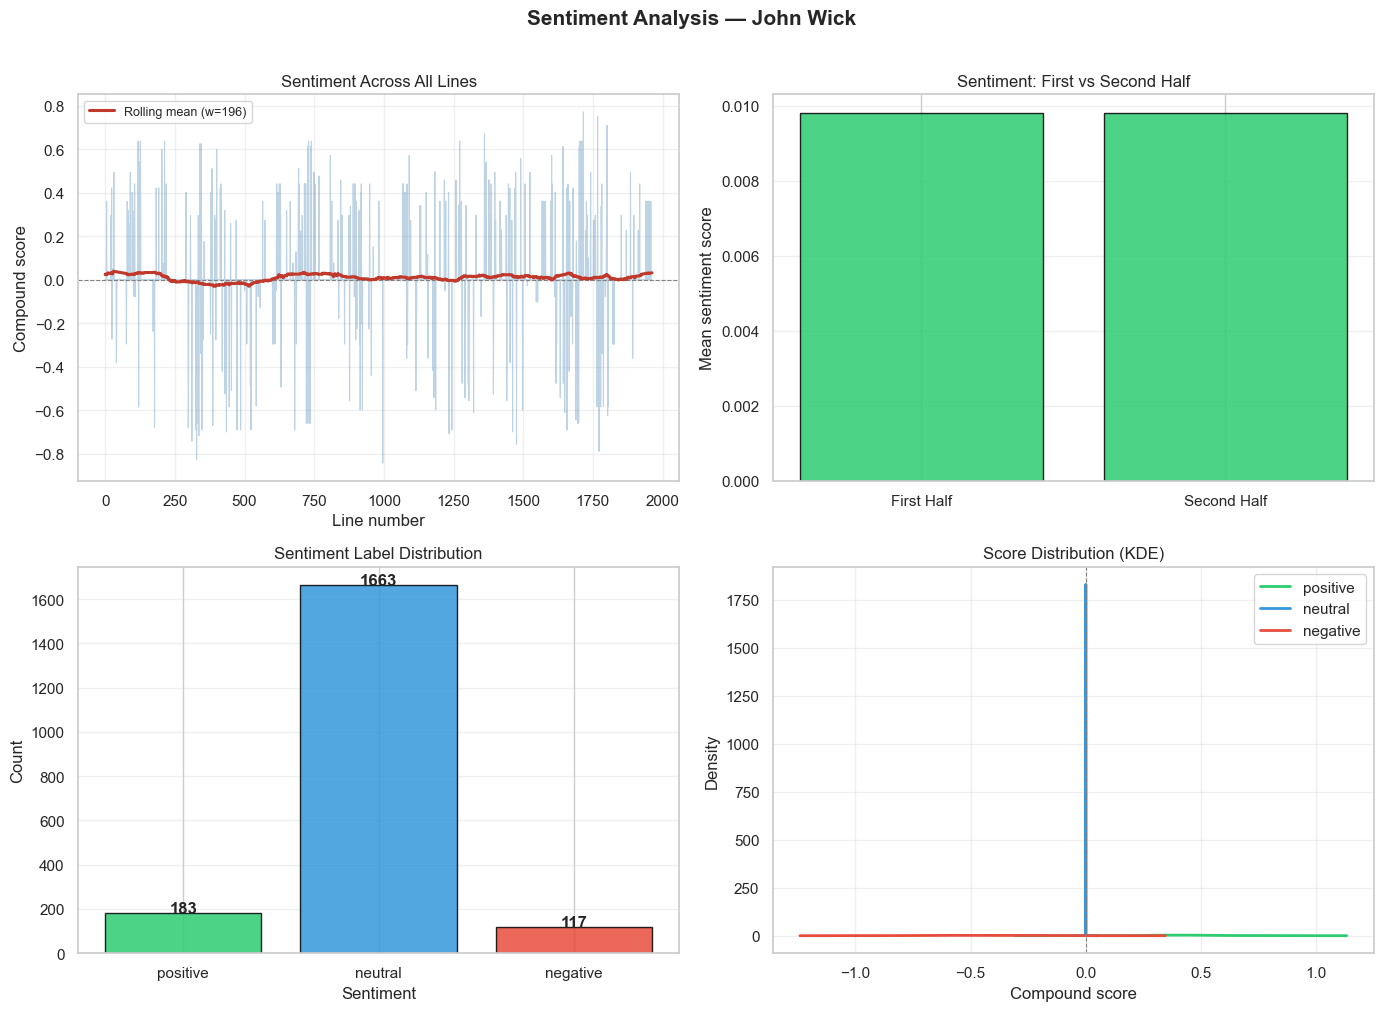

 Saved → sentiment_analysis.png


In [10]:
#Step 7 — Visualisation
COLORS = {"positive": "#2ecc71", "neutral": "#3498db", "negative": "#e74c3c"}

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle(f"Sentiment Analysis — {show_name}", fontsize=15, fontweight="bold", y=1.01)

# 1. Sentiment over all lines
ax = axes[0, 0]
ax.plot(df["score"].values, alpha=0.35, color="steelblue", linewidth=0.8)
ax.axhline(0, color="grey", linestyle="--", linewidth=0.8)
win = max(5, len(df) // 10)
rolling = pd.Series(df["score"].values).rolling(win, center=True, min_periods=1).mean()
ax.plot(rolling.values, color="#c0392b", linewidth=2.2, label=f"Rolling mean (w={win})")
ax.set_title("Sentiment Across All Lines")
ax.set_xlabel("Line number"); ax.set_ylabel("Compound score")
ax.legend(fontsize=9); ax.grid(alpha=0.3)

# 2. Per-segment bar chart
ax = axes[0, 1]
seg_sent = df.groupby("segment")["score"].mean()
bar_colors = ["#2ecc71" if v >= 0 else "#e74c3c" for v in seg_sent.values]
if is_tv:
    x_labels = [f"Ep {s}" for s in seg_sent.index]
    ax.set_title("Average Sentiment per Episode")
else:
    x_labels = ["First Half", "Second Half"]
    ax.set_title("Sentiment: First vs Second Half")
ax.bar(x_labels, seg_sent.values, color=bar_colors, alpha=0.85, edgecolor="black")
ax.axhline(0, color="grey", linestyle="--", linewidth=0.8)
ax.set_ylabel("Mean sentiment score"); ax.grid(axis="y", alpha=0.3)

# 3. Label distribution
ax = axes[1, 0]
counts = df["label"].value_counts().reindex(["positive", "neutral", "negative"])
ax.bar(counts.index, counts.values, color=[COLORS[l] for l in counts.index],
       alpha=0.85, edgecolor="black")
ax.set_title("Sentiment Label Distribution")
ax.set_xlabel("Sentiment"); ax.set_ylabel("Count"); ax.grid(axis="y", alpha=0.3)
for i, v in enumerate(counts.values):
    ax.text(i, v + 0.5, str(v), ha="center", fontweight="bold")

# 4. KDE distribution
ax = axes[1, 1]
for lbl, col in COLORS.items():
    sub = df[df["label"] == lbl]["score"]
    if len(sub) > 1:
        sub.plot.kde(ax=ax, label=lbl, color=col, linewidth=2)
ax.axvline(0, color="grey", linestyle="--", linewidth=0.8)
ax.set_title("Score Distribution (KDE)")
ax.set_xlabel("Compound score"); ax.legend(); ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("sentiment_analysis.png", dpi=110, bbox_inches="tight")
plt.show()
print(" Saved → sentiment_analysis.png")

In [11]:
'''Step 8 — ML Genre Classification (TF-IDF + Logistic Regression)
A small labelled dataset of 45 lines covers comedy / drama / action.
The model is trained on this data and then predicts the genre of your show.'''
# ── Labelled genre dataset ─────
GENRE_DATA = {
    "comedy": [
        "That is absolutely hilarious I can't stop laughing",
        "You're such a clown always making everyone laugh",
        "Ha ha this is the funniest thing I have ever seen",
        "I'm cracking up right now this is too good",
        "You've got to be kidding me that's ridiculous",
        "Oh stop it you're killing me with these jokes",
        "Best prank ever I can't believe you pulled that off",
        "I almost spit out my drink from laughing so hard",
        "This is comedy gold pure genius right here",
        "Your face when you realized it was a joke priceless",
        "Every time you tell that story I completely lose it",
        "I love how nothing ever seems to go right for you",
        "The look on his face was absolutely priceless",
        "You seriously just tripped over nothing again",
        "I can't take you anywhere without something funny happening",
        "Dude we lost the car again how does that even happen",
        "I swear this made sense in my head five minutes ago",
        "You had one job and somehow you made it worse",
        "Why are we like this every single time",
        "This is already a disaster and we just got here",
        "Did you really think that plan would actually work",
        "I woke up and everything is somehow worse than before",
         "This is exactly why nobody trusts us with anything",
        "We are so getting fired for this",
        "I cannot believe we are running from our own mistake again",
        "That might be the dumbest idea you have ever had",
        "We peaked five minutes ago it is all downhill from here",
        "Tell me this is a joke please tell me this is a joke",
        "You turned a small problem into a full blown crisis",
        "I need a minute to process how stupid that was",
    ],
    "drama": [
        "I can't believe you would betray me after everything",
        "The weight of this secret is destroying me from within",
        "Why can't you understand how much pain I carry",
        "This family is falling apart and nobody even cares",
        "I gave up everything for you and this is what I get",
        "The truth is out now and nothing will ever be same",
        "I thought you loved me but I was clearly wrong",
        "After all these years how could you just walk away",
        "My heart is broken and I don't know who you are",
        "Some wounds never heal no matter how much time passes",
        "I've been carrying this guilt alone for so long",
        "Please don't leave me I cannot do this without you",
        "Everything I believed in has turned out to be a lie",
        "How do you live with yourself after what you've done",
        "This is the end and I hope you know that",
        "You knew the truth and you let me believe the lie",
        "I do not even recognize the person you have become",
        "We used to mean something to each other what happened",
        "This silence between us says more than words ever could",
        "I stayed when everyone else walked away and this is my reward",
        "You broke something in me that will never heal",
        "I wish things had turned out differently for us",
        "We cannot keep pretending everything is fine",
        "Every choice we made led us to this moment",
        "I wanted to believe in you more than anything",
        "This is not anger anymore it is just disappointment",
        "You do not get to rewrite what happened",
        "Some endings are not meant to be happy",
        "I gave you my trust and you shattered it",
        "There is nothing left for me here anymore",
    ],
    "action": [
        "Move now or we are all dead take cover immediately",
        "Fire on my command do not let them escape alive",
        "We've got hostiles incoming brace for impact now",
        "Target acquired preparing to engage get ready soldiers",
        "The bomb is armed we have thirty seconds to defuse",
        "Get down and stay down until I give the all clear",
        "We are surrounded on all sides we need backup now",
        "Take him out before he reaches the detonator",
        "Hold your position and under no circumstances retreat",
        "Mission is compromised abort abort get out of there",
        "Cover me while I take out the guard on the left",
        "Perimeter is breached all units report immediately now",
        "We have to move through enemy lines before dawn breaks",
        "There is no time for talking we have to fight",
        "Lock and load we hit the compound in five minutes",
        "We are out of time move move move",
        "Stay sharp they could hit us from anywhere",
        "If we fail here there is no second chance",
        "Get the package and get out do not engage",
        "We go in fast and we get out faster",
        "Eyes up this is where it gets dangerous",
        "Do not think just react and keep moving",
        "We have one shot at this do not miss",
        "They are closing in we need an exit now",
        "Stick to the plan no improvisation this time",
        "I need cover fire now or we are done",
        "This mission was never supposed to be easy",
        "We either finish this or we do not come back",
        "Trust your training and push forward",
        "No hesitation take the shot",
    ],
    "thriller": [
    "Someone is watching us I can feel it",
    "This does not add up something is very wrong",
    "Why is the door already open",
    "Do not trust anyone until we know the truth",
    "I heard something and it was not just the wind",
    "We are missing a piece of this puzzle",
    "This place gives me a really bad feeling",
    "If they find us it is over",
    "There is something you are not telling me",
    "We should not be here right now",
    "Every step we take makes it worse",
    "I think we are being followed",
    "This is bigger than we thought",
    "We walked straight into a trap",
    "Keep your voice down and stay close",
    ],
    "sci_fi": [
    "The system is evolving beyond our control",
    "We are not alone out here anymore",
    "Time does not work the way we thought it did",
    "This technology is centuries ahead of us",
    "The signal is coming from inside the system",
    "Reality might not be what we think it is",
    "We opened something we cannot close",
    "The experiment has gone too far",
    "We are rewriting the rules of existence",
    "This changes everything we know about the universe",
    "The AI is making its own decisions now",
    "We crossed a boundary we did not understand",
    "There is no turning back after this",
    "The anomaly is growing rapidly",
    "We were never supposed to find this",
    ],
    "romance": [
    "I did not expect to fall for you like this",
    "You make everything feel a little less heavy",
    "I keep finding my way back to you",
    "Being with you just feels right",
    "I am scared but I want to try",
    "You are the only one who truly understands me",
    "I never believed in this until I met you",
    "We are a mess but somehow it works",
    "I would choose you every single time",
    "You changed my life without even trying",
    "I cannot imagine my future without you",
    "Even when we fight I still want us",
    "You see me in a way no one else does",
    "I think this might be love",
    "Let us not ruin what we have",
    ],
    "horror": [
    "Did you hear that it came from upstairs",
    "Do not turn around just keep walking",
    "Something is very wrong with this place",
    "We should have never come here",
    "It knows we are here",
    "The lights went out again",
    "There is something behind that door",
    "We are not alone in this house",
    "It keeps getting closer every second",
    "Why is it so quiet all of a sudden",
    "I saw something move in the dark",
    "This is not going to end well",
    "We need to leave right now",
    "It is already inside",
    "Do not make a sound",
    ]
}

texts, labels = [], []
for genre, lines in GENRE_DATA.items():
    texts.extend(lines)
    labels.extend([genre] * len(lines))

LABEL2ID = {"comedy": 0, "drama": 1, "action": 2,"thriller": 3,"sci_fi": 4,"romance": 5,"horror": 6}
ID2LABEL  = {v: k for k, v in LABEL2ID.items()}
y         = np.array([LABEL2ID[l] for l in labels])

# TF-IDF (fit on genre data + user's subtitle text for better vocab)
user_texts = df["original"].tolist()
tfidf      = TfidfVectorizer(max_features=1200, ngram_range=(1, 2))
tfidf.fit(texts + user_texts)

X      = tfidf.transform(texts).toarray()
X_user = tfidf.transform(user_texts).toarray()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)

lr = LogisticRegression(max_iter=500, random_state=42)
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

print(" Logistic Regression trained!")
print(f"   Test accuracy : {accuracy_score(y_test, y_pred_lr):.2%}")

 Logistic Regression trained!
   Test accuracy : 31.58%


In [13]:
#Step 9 — Simple Dense Neural Network (Keras)
n_classes  = 7
y_cat      = to_categorical(y, num_classes=n_classes)

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y_cat, test_size=0.25, random_state=42)

# ── Model architecture ─────
model = Sequential([
    Dense(128, activation="relu", input_shape=(X.shape[1],)),
    Dropout(0.3),
    Dense(64,  activation="relu"),
    Dropout(0.3),
    Dense(n_classes, activation="softmax"),
])
model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
model.summary()

# ── Training ───────────
history = model.fit(X_tr, y_tr,
                    epochs=40, batch_size=8,
                    validation_data=(X_te, y_te),
                    verbose=0)

y_pred_nn = np.argmax(model.predict(X_te, verbose=0), axis=1)
y_true_nn = np.argmax(y_te, axis=1)

print(f"\n Neural Network trained!")
print(f"   Final val accuracy : {history.history['val_accuracy'][-1]:.2%}")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 128)                 │         153,728 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 7)                   │             455 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 162,439 (634.53 KB)

 Trainable params: 162,439 (634.53 KB)

 Non-trainable params: 0 (0.00 B)


 Neural Network trained!
   Final val accuracy : 28.95%



════════════════════════════════════════════════════
  LOGISTIC REGRESSION
════════════════════════════════════════════════════
  Accuracy  : 31.58%
  Precision : 27.83%
  Recall    : 31.58%
  F1-Score  : 25.56%

              precision    recall  f1-score   support

      comedy       0.25      0.29      0.27         7
       drama       0.25      0.57      0.35         7
      action       0.38      0.62      0.48         8
    thriller       0.00      0.00      0.00         4
      sci_fi       1.00      0.25      0.40         4
     romance       0.00      0.00      0.00         4
      horror       0.00      0.00      0.00         4

    accuracy                           0.32        38
   macro avg       0.27      0.25      0.21        38
weighted avg       0.28      0.32      0.26        38


════════════════════════════════════════════════════
  NEURAL NETWORK  (Dense)
════════════════════════════════════════════════════
  Accuracy  : 28.95%
  Precision : 34.77%
  Recall    : 

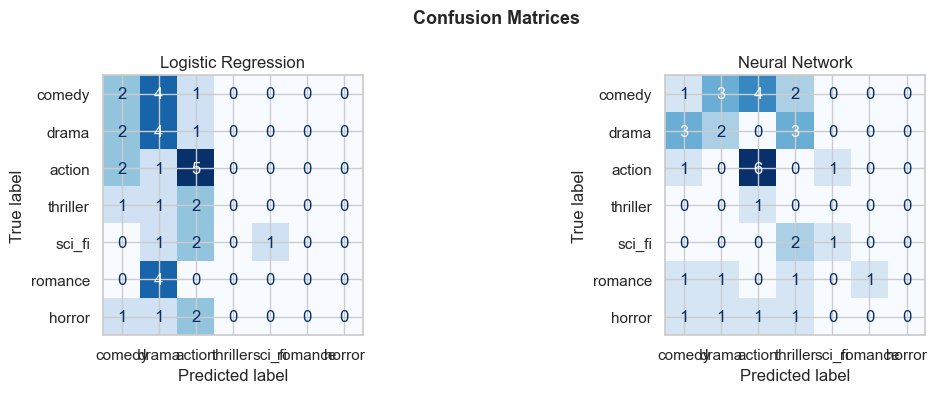

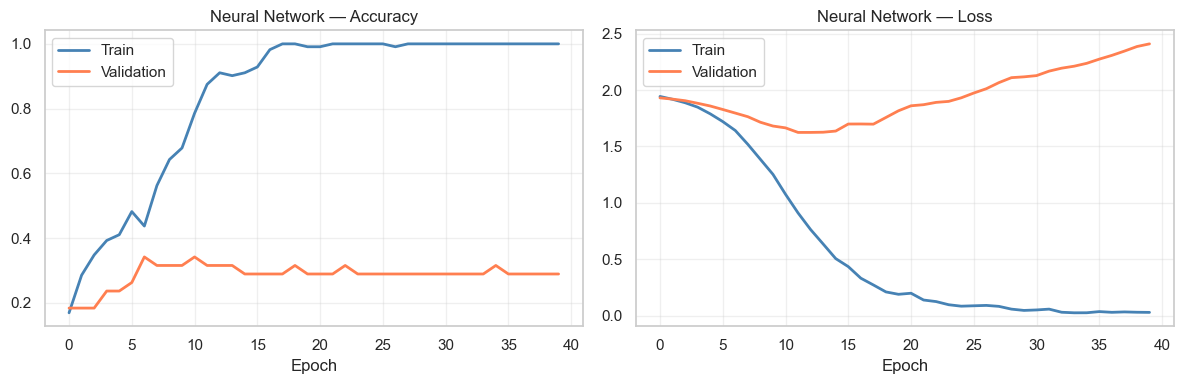


════════════════════════════════════════════════════
    Genre Prediction for  "John Wick"
════════════════════════════════════════════════════
  comedy                                  20.7%
  drama                                   20.8%
  action                                  18.4%
  thriller                                9.7%
  sci_fi                                  8.8%
  romance                                 10.9%
  horror                                  10.7%

    Predicted genre : DRAMA

 Analysis complete! 


In [15]:
#Step 10 — Evaluation & Results
LABEL_NAMES = ["comedy", "drama", "action", "thriller", "sci_fi", "romance", "horror"]

def show_metrics(y_true, y_pred, name):
    print(f"\n{'═'*52}")
    print(f"  {name}")
    print(f"{'═'*52}")
    print(f"  Accuracy  : {accuracy_score(y_true, y_pred):.2%}")
    print(f"  Precision : {precision_score(y_true, y_pred, average='weighted', zero_division=0):.2%}")
    print(f"  Recall    : {recall_score(y_true, y_pred, average='weighted', zero_division=0):.2%}")
    print(f"  F1-Score  : {f1_score(y_true, y_pred, average='weighted', zero_division=0):.2%}")
    print()
    print(classification_report(y_true, y_pred, target_names=LABEL_NAMES, zero_division=0))

show_metrics(y_test,    y_pred_lr, "LOGISTIC REGRESSION")
show_metrics(y_true_nn, y_pred_nn, "NEURAL NETWORK  (Dense)")

# ── Confusion matrices ─────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle("Confusion Matrices", fontsize=13, fontweight="bold")
for ax, yt, yp, title in [
    (axes[0], y_test,    y_pred_lr, "Logistic Regression"),
    (axes[1], y_true_nn, y_pred_nn, "Neural Network"),
]:
    ConfusionMatrixDisplay(confusion_matrix(yt, yp),
                           display_labels=LABEL_NAMES).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(title)
plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=110, bbox_inches="tight")
plt.show()

# ── Training curves ────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric, title in [
    (axes[0], "accuracy", "Accuracy"),
    (axes[1], "loss",     "Loss"),
]:
    ax.plot(history.history[metric],          label="Train",      color="steelblue", linewidth=2)
    ax.plot(history.history[f"val_{metric}"], label="Validation", color="coral",     linewidth=2)
    ax.set_title(f"Neural Network — {title}"); ax.set_xlabel("Epoch")
    ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("training_curves.png", dpi=110, bbox_inches="tight")
plt.show()

# ── Genre prediction for user's show ────
avg_probs       = lr.predict_proba(X_user).mean(axis=0)
predicted_genre = LABEL_NAMES[np.argmax(avg_probs)]

print(f"\n{'═'*52}")
print(f"    Genre Prediction for  \"{show_name}\"")
print(f"{'═'*52}")
for g, p in zip(LABEL_NAMES, avg_probs):
    bar = "" * int(p * 28)
    print(f"  {g:8s}  {bar:<28}  {p:.1%}")
print(f"\n    Predicted genre : {predicted_genre.upper()}")
print("\n Analysis complete! ")